# Plotting magnon dispersions with NumPy

This notebook goes with the <a href="https://wuzhangfang.github.io/tutorials/linear-spin-wave-theory/" target="_top">linear spin-wave theory</a> tutorial. It uses the result

$$\hbar\omega_{\mathbf{k}} = zJS\,(1-\gamma_{\mathbf{k}}), \qquad \gamma_{\mathbf{k}} = \frac{1}{z}\sum_{\boldsymbol\delta} e^{i\mathbf{k}\cdot\boldsymbol\delta}$$

to plot magnon dispersions of nearest-neighbor Heisenberg ferromagnets and check the long-wavelength limit $\hbar\omega \approx Dk^2$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def magnon_energy(kpts, neighbors, J=1.0, S=1.0):
    """hbar*omega_k = z J S (1 - gamma_k) for a nearest-neighbor Heisenberg ferromagnet."""
    z = len(neighbors)
    gamma = np.cos(kpts @ neighbors.T).mean(axis=1)
    return z * J * S * (1.0 - gamma)

def kpath(points, n=100):
    """Straight-line path through high-symmetry points. Returns k-points, distance along path, tick positions."""
    segs, dist, ticks, d0 = [], [], [0.0], 0.0
    for p, q in zip(points[:-1], points[1:]):
        t = np.linspace(0, 1, n, endpoint=False)[:, None]
        seg = p + t * (q - p)
        segs.append(seg)
        dist.append(d0 + np.linalg.norm(seg - p, axis=1))
        d0 += np.linalg.norm(q - p)
        ticks.append(d0)
    k = np.vstack(segs + [points[-1][None, :]])
    x = np.concatenate(dist + [[d0]])
    return k, x, ticks

## Square and triangular lattices

Lattice constant $a = 1$, $J = S = 1$. For the triangular lattice, the high-symmetry points are $\mathrm{M} = (\pi, \pi/\sqrt3)$ and $\mathrm{K} = (4\pi/3, 0)$.

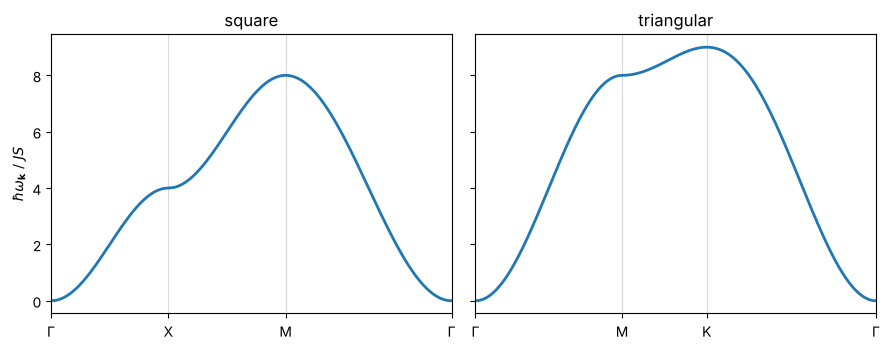

    square: bandwidth = 8.000 JS
triangular: bandwidth = 9.000 JS


In [2]:
lattices = {
    "square": {
        "neighbors": np.array([[1, 0], [-1, 0], [0, 1], [0, -1]], float),
        "path": [("Γ", [0, 0]), ("X", [np.pi, 0]), ("M", [np.pi, np.pi]), ("Γ", [0, 0])],
    },
    "triangular": {
        "neighbors": np.array([[np.cos(t), np.sin(t)] for t in np.arange(6) * np.pi / 3]),
        "path": [("Γ", [0, 0]), ("M", [np.pi, np.pi / np.sqrt(3)]), ("K", [4 * np.pi / 3, 0]), ("Γ", [0, 0])],
    },
}

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, (name, lat) in zip(axes, lattices.items()):
    labels = [p[0] for p in lat["path"]]
    pts = np.array([p[1] for p in lat["path"]], float)
    k, x, ticks = kpath(pts)
    E = magnon_energy(k, lat["neighbors"])
    ax.plot(x, E, lw=2)
    ax.set_xticks(ticks, labels)
    for t in ticks:
        ax.axvline(t, color="0.85", lw=0.8, zorder=0)
    ax.set_xlim(x[0], x[-1])
    ax.set_title(name)
axes[0].set_ylabel(r"$\hbar\omega_\mathbf{k}\ /\ JS$")
fig.tight_layout()
plt.show()

for name, lat in lattices.items():
    pts = np.array([p[1] for p in lat["path"]], float)
    k, _, _ = kpath(pts)
    print(f"{name:>10}: bandwidth = {magnon_energy(k, lat['neighbors']).max():.3f} JS")

The bandwidth is $8JS$ for the square lattice (at M) and $9JS$ for the triangular lattice (at K, where $\gamma_{\mathrm{K}} = -1/2$).

## Checking the $Dk^2$ limit

Near $\Gamma$ the dispersion should approach $Dk^2$, with $D = JSa^2$ (square) and $D = \tfrac32 JSa^2$ (triangular). Fit the first few points along $k_x$:

In [3]:
k_small = np.linspace(1e-3, 0.1, 20)
kpts = np.column_stack([k_small, np.zeros_like(k_small)])
expected = {"square": 1.0, "triangular": 1.5}

for name, lat in lattices.items():
    E = magnon_energy(kpts, lat["neighbors"])
    D_fit = np.polyfit(k_small**2, E, 1)[0]
    print(f"{name:>10}: D_fit = {D_fit:.4f},  expected = {expected[name]:.4f}  (units of JSa^2)")

    square: D_fit = 0.9993,  expected = 1.0000  (units of JSa^2)
triangular: D_fit = 1.4992,  expected = 1.5000  (units of JSa^2)


Both fits agree with the analytic stiffness to within the small $k^4$ correction.

**Try it yourself:** add a single-ion anisotropy, $-K\sum_i (S_i^z)^2$. In linear spin-wave theory, it shifts every energy up by a constant gap $\Delta = 2KS$. The exact one-magnon gap is $(2S-1)K$, and the difference matters for small $S$.